In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
# ===== Cell 01 of 14: Install required libraries =====

"""
CBL Research Screening Test: Questions 1-3 (Pritha Saha)
PneumoniaMNIST (MedMNIST v2, 224 x 224) + ImageNet-pretrained ResNet-18.

Kaggle setup: Accelerator = GPU T4, Internet = On, notebook kept private.
Paste files 01 to 14 into 14 separate code cells, in order, and run them top to bottom.
Quick check first: in cell 02 set FAST_DEV_RUN = True (about 10 min), then set it
back to False and use Run All for the real results (about 60-90 min on a T4).
Figures show under each cell and are saved to /kaggle/working/outputs.
"""

# ----------------------------- library installation -----------------------------
import importlib, subprocess, sys

REQUIRED = {                 # import name -> pip package name
    "torch": "torch",
    "torchvision": "torchvision",
    "medmnist": "medmnist",
    "optuna": "optuna",
    "sklearn": "scikit-learn",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", " ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

Installing: medmnist
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 6.4 MB/s eta 0:00:00


In [3]:
# ===== Cell 02 of 14: Imports, configuration, device =====
# Run the cells in order. Each cell uses variables created by the previous ones.

import os, time, json, random, copy, hashlib, warnings
import numpy as np
import pandas as pd
import argparse, multiprocessing
import matplotlib
try:                           # running inside a Jupyter/Kaggle notebook cell?
    get_ipython()               # noqa: F821
    IN_NOTEBOOK = True
except NameError:
    IN_NOTEBOOK = False
if not IN_NOTEBOOK:
    matplotlib.use("Agg")       # plain script: save figures to files only
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models
from torchvision.transforms import v2 as T

from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             confusion_matrix, f1_score, accuracy_score,
                             balanced_accuracy_score, log_loss)
import medmnist
from medmnist import PneumoniaMNIST, INFO
import optuna

warnings.filterwarnings("ignore", category=UserWarning)

# ----------------------------- configuration -----------------------------
# >>> Set FAST_DEV_RUN = True for a quick pipeline check (1 epoch, 2 tuning trials, ~10 min).
# >>> Set it back to False for the real run.
FAST_DEV_RUN = False
parser = argparse.ArgumentParser()
parser.add_argument("--fast", action="store_true", help="same as FAST_DEV_RUN = True")
args, _ = parser.parse_known_args()
FAST_DEV_RUN = FAST_DEV_RUN or args.fast

if sys.platform.startswith("linux"):
    multiprocessing.set_start_method("fork", force=True)   # data-loader workers in a script

def show_fig():
    # show figures inline in a notebook; just close them when run as a script
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close()

def display(df):
    # print a table in full (replacement for notebook display)
    with pd.option_context("display.max_columns", None, "display.width", 200):
        print(df.to_string() if hasattr(df, "to_string") else df)

CFG = dict(
    seed=42,
    img_size=224,             # MedMNIST+ offers 28, 64, 128, 224
    batch_size=64,
    epochs=12,
    lr=1e-4,
    weight_decay=1e-4,
    dropout=0.0,
    aug="light",              # "none" | "light" | "strong"
    patience=4,               # early stopping patience (epochs)
    select_metric="val_loss", # model selection / early stopping / tuning on validation loss
                              # (validation AUROC is ~0.999, too saturated to rank models)
    threshold=0.5,            # main operating point; the validation-Youden threshold is reported as secondary
    num_workers=4,
    amp=True,                 # mixed precision on GPU
    channels_last=False,
    n_trials=20,              # Optuna trials (Q3)
    trial_epochs=8,           # epochs per Optuna trial (closer to the 12-epoch final training)
    seeds=[42, 43, 44],       # repeated runs for the Q3 comparisons
)
REMOVE_DUPLICATES = True          # drop exact duplicates in train/val and val images also in train
RUN_FP32_ACCURACY_CHECK = True    # Q3: does mixed precision change accuracy?
RUN_RESOLUTION_EXPERIMENT = True  # Q3: 128 px vs 224 px speed/accuracy trade-off

if FAST_DEV_RUN:
    CFG.update(epochs=1, n_trials=2, trial_epochs=1, seeds=[42, 43])

OUT_DIR = "/kaggle/working/outputs" if os.path.isdir("/kaggle/working") else "./outputs"
DATA_ROOT = os.path.join(os.path.dirname(OUT_DIR), "medmnist_data")
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(DATA_ROOT, exist_ok=True)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
USE_AMP = CFG["amp"] and DEVICE.type == "cuda"

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(CFG["seed"])
torch.backends.cudnn.benchmark = True   # faster convolutions (small run-to-run nondeterminism)

print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__,
      "| medmnist", medmnist.__version__, "| optuna", optuna.__version__)
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
print("Outputs ->", OUT_DIR)

PyTorch 2.11.0+cu128 | torchvision 0.26.0+cu128 | medmnist 3.0.2 | optuna 5.0.0
Device: cuda:0 Tesla T4
Outputs -> /kaggle/working/outputs


In [4]:
# ===== Cell 03 of 14: Q1: load PneumoniaMNIST =====
# Run the cells in order. Each cell uses variables created by the previous ones.

# ## Question 1
# **1. Implement an AI model using a framework of your choice (e.g., TensorFlow, PyTorch) to perform a binary classification task.**
# - a. You may use any available dataset or create a synthetic one. Briefly describe.
# - b. Explain your choices for the loss function, optimization algorithm, and evaluation metrics.
# - c. Briefly explain how you handled any class imbalance, missing values, or other pre-processing requirements.
# - d. What observations can be drawn about your model's performance, the data, or the modeling process?

# ### 1.1 Load the data

LABELS = {int(k): v for k, v in INFO["pneumoniamnist"]["label"].items()}   # {0: 'normal', 1: 'pneumonia'}

def load_split(split, size):
    ds = PneumoniaMNIST(split=split, download=True, size=size, root=DATA_ROOT)
    X = np.ascontiguousarray(ds.imgs)                 # (N, H, W) uint8
    if X.ndim == 4:                                   # safety: keep a single channel
        X = X[..., 0]
    y = ds.labels.reshape(-1).astype(np.int64)        # 0 = normal, 1 = pneumonia
    return X, y

data = {s: load_split(s, CFG["img_size"]) for s in ["train", "val", "test"]}
print("Labels:", LABELS)
for s, (X, y) in data.items():
    print(f"{s:5s}: images {X.shape}, dtype {X.dtype}, labels {y.shape}")

100%|██████████| 214M/214M [00:40<00:00, 5.30MB/s]


Labels: {0: 'normal', 1: 'pneumonia'}
train: images (4708, 224, 224), dtype uint8, labels (4708,)
val  : images (524, 224, 224), dtype uint8, labels (524,)
test : images (624, 224, 224), dtype uint8, labels (624,)


Class balance (original official splits)
       total  normal  pneumonia  pct_pneumonia  ratio_pneu_to_normal
split                                                               
train   4708    1214       3494           74.2                  2.88
val      524     135        389           74.2                  2.88
test     624     234        390           62.5                  1.67

Integrity checks
  train: NaN pixels=0, constant (blank) images=0, invalid labels=0, pixel range=[0, 255]
  val  : NaN pixels=0, constant (blank) images=0, invalid labels=0, pixel range=[0, 255]
  test : NaN pixels=0, constant (blank) images=0, invalid labels=0, pixel range=[0, 255]
  duplicates inside train: 18 (copies with conflicting labels: 0)
  duplicates inside val  : 0 (copies with conflicting labels: 0)
  duplicates inside test : 3 (copies with conflicting labels: 0)
  identical images shared by train/val: 8
  identical images shared by train/test: 0
  identical images shared by val/test: 0

Remove

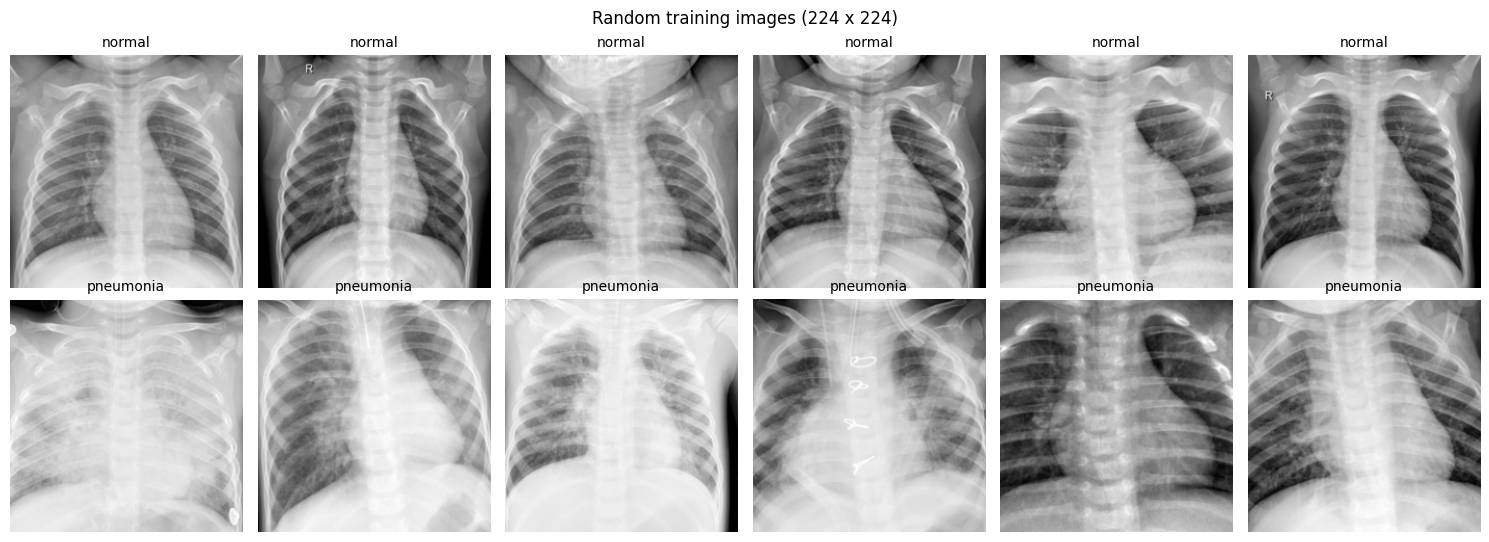

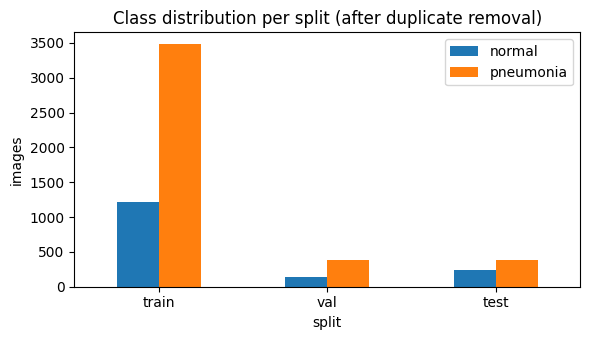

In [5]:
# ===== Cell 04 of 14: Q1: class balance, integrity checks, duplicate removal, sample images =====
# Run the cells in order. Each cell uses variables created by the previous ones.

# ### 1.2 Data exploration and integrity checks (supports Q1a, Q1c)

def class_balance(data):
    rows = []
    for s, (X, y) in data.items():
        n0, n1 = int((y == 0).sum()), int((y == 1).sum())
        rows.append(dict(split=s, total=len(y), normal=n0, pneumonia=n1,
                         pct_pneumonia=round(100 * n1 / len(y), 1),
                         ratio_pneu_to_normal=round(n1 / n0, 2)))
    return pd.DataFrame(rows).set_index("split")

print("Class balance (original official splits)")
balance_raw = class_balance(data)
display(balance_raw)
balance_raw.to_csv(f"{OUT_DIR}/class_balance_original.csv")

# ---- missing / corrupted data checks ----
print("\nIntegrity checks")
for s, (X, y) in data.items():
    Xf = X.astype(np.float32)
    n_nan = int(np.isnan(Xf).sum())
    n_constant = int((X.reshape(len(X), -1).std(axis=1) == 0).sum())   # blank images
    bad_labels = int((~np.isin(y, [0, 1])).sum())
    print(f"  {s:5s}: NaN pixels={n_nan}, constant (blank) images={n_constant}, "
          f"invalid labels={bad_labels}, pixel range=[{X.min()}, {X.max()}]")

# ---- exact duplicate images within and across splits (possible leakage) ----
hashes = {s: np.array([hashlib.md5(img.tobytes()).hexdigest() for img in X]) for s, (X, _) in data.items()}

def label_conflicts(h, y):
    # number of duplicated images whose copies carry different labels
    df = pd.DataFrame({"h": h, "y": y})
    g = df.groupby("h").y.nunique()
    return int((g > 1).sum())

dup_report = {}
for s in hashes:
    n_dup = len(hashes[s]) - len(set(hashes[s]))
    dup_report[f"duplicates inside {s}"] = n_dup
    print(f"  duplicates inside {s:5s}: {n_dup} (copies with conflicting labels: "
          f"{label_conflicts(hashes[s], data[s][1])})")
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    shared = set(hashes[a]) & set(hashes[b])
    dup_report[f"shared {a}/{b}"] = len(shared)
    print(f"  identical images shared by {a}/{b}: {len(shared)}")

# ---- remove duplicates (train and validation only; the official test set is kept intact) ----
DEDUP_MASKS = None   # reused in Q3 to apply the same removal to the 128 px version
if REMOVE_DUPLICATES:
    def keep_first(h):
        _, first = np.unique(h, return_index=True)
        mask = np.zeros(len(h), dtype=bool); mask[first] = True
        return mask

    keep_tr = keep_first(hashes["train"])
    keep_va = keep_first(hashes["val"]) & ~np.isin(hashes["val"], hashes["train"][keep_tr])
    DEDUP_MASKS = {"train": keep_tr, "val": keep_va}
    removed = {"train": int((~keep_tr).sum()), "val": int((~keep_va).sum())}
    data["train"] = (data["train"][0][keep_tr], data["train"][1][keep_tr])
    data["val"] = (data["val"][0][keep_va], data["val"][1][keep_va])
    print(f"\nRemoved {removed['train']} duplicate images from train and {removed['val']} from validation "
          f"(within-split copies and validation images also present in train).")
    print("The official test set is unchanged so results stay comparable with the benchmark; "
          f"it contains {dup_report['duplicates inside test']} within-test duplicate(s).")
    dup_report.update({f"removed from {k}": v for k, v in removed.items()})

pd.Series(dup_report).to_csv(f"{OUT_DIR}/duplicate_report.csv")
print("\nClass balance used for training and evaluation")
balance = class_balance(data)
display(balance)
balance.to_csv(f"{OUT_DIR}/class_balance.csv")

# ---- intensity statistics by split and class ----
stats = []
for s, (X, y) in data.items():
    for c in [0, 1]:
        m = X[y == c].reshape((y == c).sum(), -1).mean(axis=1)
        stats.append(dict(split=s, cls=LABELS[c], mean_intensity=m.mean(), std_of_means=m.std()))
display(pd.DataFrame(stats).round(2))

fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
Xtr, ytr = data["train"]
rng = np.random.default_rng(0)
for r, c in enumerate([0, 1]):
    idx = rng.choice(np.where(ytr == c)[0], 6, replace=False)
    for k, i in enumerate(idx):
        axes[r, k].imshow(Xtr[i], cmap="gray"); axes[r, k].axis("off")
        axes[r, k].set_title(LABELS[c], fontsize=10)
plt.suptitle("Random training images (224 x 224)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/sample_images.png", dpi=120); show_fig()

ax = balance[["normal", "pneumonia"]].plot.bar(figsize=(6, 3.5), rot=0)
ax.set_ylabel("images"); ax.set_title("Class distribution per split (after duplicate removal)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/class_distribution.png", dpi=120); show_fig()

In [6]:
# ===== Cell 05 of 14: Q1: preprocessing, augmentation, data loaders =====
# Run the cells in order. Each cell uses variables created by the previous ones.

# ### 1.3 Pre-processing, augmentation and data loaders

IMNET_MEAN, IMNET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

def build_aug(level):
    # Mild geometric and intensity changes. No horizontal flips: chest X-rays have
    # a fixed left/right anatomy (e.g. heart on the left), so flips create unrealistic images.
    if level == "none":
        return None
    if level == "light":
        return T.Compose([
            T.RandomAffine(degrees=7, translate=(0.05, 0.05), scale=(0.95, 1.05)),
            T.ColorJitter(brightness=0.1, contrast=0.1),
        ])
    if level == "strong":
        return T.Compose([
            T.RandomAffine(degrees=15, translate=(0.10, 0.10), scale=(0.85, 1.15)),
            T.ColorJitter(brightness=0.2, contrast=0.2),
        ])
    raise ValueError(level)

class XrayDataset(Dataset):
    # Grayscale uint8 array -> augmented, normalized 3-channel float tensor.
    def __init__(self, X, y, aug="none"):
        self.X, self.y = X, y
        self.aug = build_aug(aug)
        self.norm = T.Normalize(IMNET_MEAN, IMNET_STD)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        x = torch.from_numpy(self.X[i]).unsqueeze(0)       # (1, H, W) uint8
        if self.aug is not None:
            x = self.aug(x)
        x = x.float().div(255.0).repeat(3, 1, 1)           # 3 channels for ImageNet weights
        x = self.norm(x)
        return x, torch.tensor(self.y[i], dtype=torch.float32)

def make_loader(split_data, batch_size, aug="none", shuffle=False):
    X, y = split_data
    return DataLoader(XrayDataset(X, y, aug), batch_size=batch_size, shuffle=shuffle,
                      num_workers=CFG["num_workers"], pin_memory=(DEVICE.type == "cuda"),
                      drop_last=False, persistent_workers=CFG["num_workers"] > 0)

# Class imbalance: pneumonia (label 1) is the majority class in training.
y_train = data["train"][1]
N_NEG, N_POS = int((y_train == 0).sum()), int((y_train == 1).sum())
POS_WEIGHT = N_NEG / N_POS     # < 1, so each pneumonia example counts less than a normal one
print(f"train: normal={N_NEG}, pneumonia={N_POS}, pos_weight={POS_WEIGHT:.3f}")

xb, yb = next(iter(make_loader(data["train"], 8, CFG["aug"], shuffle=True)))
print("batch:", tuple(xb.shape), xb.dtype, "| labels:", yb.tolist())

train: normal=1213, pneumonia=3477, pos_weight=0.349
batch: (8, 3, 224, 224) torch.float32 | labels: [0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


In [7]:
# ===== Cell 06 of 14: Q1: model, training loop, metrics =====
# Run the cells in order. Each cell uses variables created by the previous ones.

# ### 1.4 Model, training loop and evaluation utilities

def build_model(dropout=0.0, pretrained=True):
    weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    m = models.resnet18(weights=weights)
    m.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.fc.in_features, 1))   # one logit
    return m

def autocast_ctx(enabled):
    return torch.autocast(device_type=DEVICE.type, dtype=torch.float16,
                          enabled=enabled and DEVICE.type == "cuda")

@torch.no_grad()
def predict(model, loader, amp=True, channels_last=False):
    model.eval(); ys, ps = [], []
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        if channels_last:
            x = x.contiguous(memory_format=torch.channels_last)
        with autocast_ctx(amp):
            logits = model(x).squeeze(1)
        ps.append(torch.sigmoid(logits.float()).cpu()); ys.append(y)
    return torch.cat(ys).numpy().astype(int), torch.cat(ps).numpy()

def train_model(cfg, data, verbose=True, trial=None):
    # Train with AdamW + cosine LR decay. Keep the epoch with the best validation score:
    # lowest validation loss (default) or highest validation AUROC (cfg['select_metric']).
    # Returns (model, history, best score of the selection metric).
    set_seed(cfg["seed"])
    amp = cfg["amp"] and DEVICE.type == "cuda"
    cl = cfg.get("channels_last", False)
    train_loader = make_loader(data["train"], cfg["batch_size"], cfg["aug"], shuffle=True)
    val_loader = make_loader(data["val"], 128, "none")

    model = build_model(cfg.get("dropout", 0.0)).to(DEVICE)
    if cl:
        model = model.to(memory_format=torch.channels_last)
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([POS_WEIGHT], device=DEVICE))
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    total_steps = cfg["epochs"] * len(train_loader)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=amp)

    use_loss = cfg.get("select_metric", "val_loss") == "val_loss"
    best_score, best_state, bad_epochs, history = (np.inf if use_loss else -np.inf), None, 0, []
    best_epoch = 1
    for epoch in range(cfg["epochs"]):
        model.train(); t0 = time.time(); loss_sum, n = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            if cl:
                x = x.contiguous(memory_format=torch.channels_last)
            optimizer.zero_grad(set_to_none=True)
            with autocast_ctx(amp):
                loss = criterion(model(x).squeeze(1), y)
            scaler.scale(loss).backward()
            scaler.step(optimizer); scaler.update(); scheduler.step()
            loss_sum += loss.item() * len(y); n += len(y)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        epoch_time = time.time() - t0

        yv, pv = predict(model, val_loader, amp, cl)
        val_auc = roc_auc_score(yv, pv)
        val_loss = log_loss(yv, np.clip(pv, 1e-7, 1 - 1e-7))
        history.append(dict(epoch=epoch + 1, train_loss=loss_sum / n,
                            val_loss=val_loss,
                            val_auroc=val_auc, epoch_time_s=epoch_time,
                            lr=optimizer.param_groups[0]["lr"]))
        if verbose:
            h = history[-1]
            print(f"epoch {h['epoch']:2d} | train_loss {h['train_loss']:.4f} | val_loss {h['val_loss']:.4f} "
                  f"| val_AUROC {val_auc:.4f} | {epoch_time:.1f}s")
        if trial is not None:
            trial.report(val_loss if use_loss else val_auc, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()
        score = val_loss if use_loss else val_auc
        improved = score < best_score if use_loss else score > best_score
        if improved:
            best_score, best_state, bad_epochs = score, copy.deepcopy(model.state_dict()), 0
            best_epoch = epoch + 1
        else:
            bad_epochs += 1
            if bad_epochs >= cfg["patience"]:
                if verbose:
                    print(f"early stopping after epoch {epoch + 1}")
                break
    model.load_state_dict(best_state)
    history = pd.DataFrame(history)
    history["selected"] = history.epoch == best_epoch      # epoch whose weights are kept
    return model, history, best_score

def compute_metrics(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(AUROC=roc_auc_score(y, p), AUPRC=average_precision_score(y, p),
                accuracy=accuracy_score(y, pred), balanced_accuracy=balanced_accuracy_score(y, pred),
                sensitivity=tp / (tp + fn), specificity=tn / (tn + fp),
                precision=tp / (tp + fp) if (tp + fp) else 0.0, F1=f1_score(y, pred),
                threshold=thr, TP=int(tp), FP=int(fp), TN=int(tn), FN=int(fn))

def youden_threshold(y, p):
    # Threshold maximizing sensitivity + specificity - 1, chosen on VALIDATION data only.
    fpr, tpr, thr = roc_curve(y, p)
    return float(np.clip(thr[np.argmax(tpr - fpr)], 0, 1))

def bootstrap_ci(y, p, fn, n=1000, seed=0):
    rng = np.random.default_rng(seed); vals = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) == 2:
            vals.append(fn(y[idx], p[idx]))
    return tuple(np.percentile(vals, [2.5, 97.5]))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 228MB/s]


epoch  1 | train_loss 0.0697 | val_loss 0.1846 | val_AUROC 0.9972 | 29.2s
epoch  2 | train_loss 0.0321 | val_loss 0.0732 | val_AUROC 0.9980 | 6.8s
epoch  3 | train_loss 0.0208 | val_loss 0.1143 | val_AUROC 0.9970 | 7.0s
epoch  4 | train_loss 0.0164 | val_loss 0.0940 | val_AUROC 0.9979 | 7.0s
epoch  5 | train_loss 0.0115 | val_loss 0.1013 | val_AUROC 0.9975 | 7.0s
epoch  6 | train_loss 0.0108 | val_loss 0.0485 | val_AUROC 0.9988 | 7.0s
epoch  7 | train_loss 0.0065 | val_loss 0.0655 | val_AUROC 0.9981 | 7.1s
epoch  8 | train_loss 0.0051 | val_loss 0.0754 | val_AUROC 0.9983 | 7.2s
epoch  9 | train_loss 0.0044 | val_loss 0.0500 | val_AUROC 0.9986 | 7.2s
epoch 10 | train_loss 0.0036 | val_loss 0.0532 | val_AUROC 0.9984 | 7.3s
early stopping after epoch 10

kept epoch 6 (lowest validation loss): val_loss = 0.0485, val AUROC = 0.9988 | training time = 1.7 min


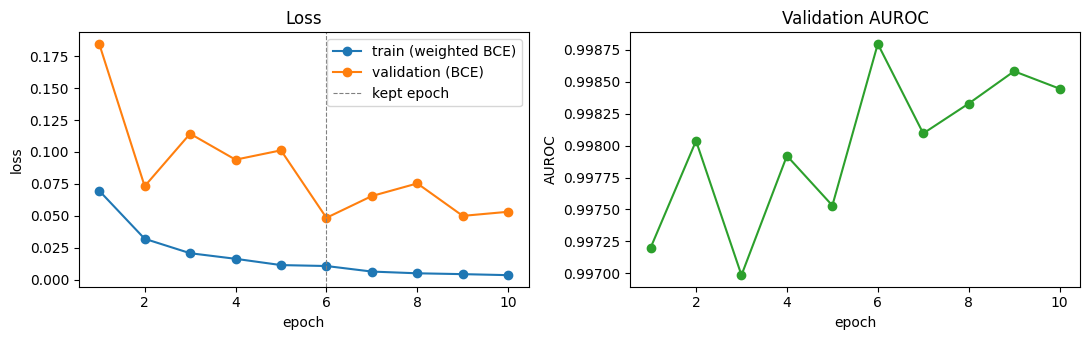

In [8]:
# ===== Cell 07 of 14: Q1: train the baseline model =====
# Run the cells in order. Each cell uses variables created by the previous ones.

# ### 1.5 Train the baseline model

t0 = time.time()
model, history, _ = train_model(CFG, data)
baseline_train_minutes = (time.time() - t0) / 60
best_row = history[history.selected].iloc[0]
print(f"\nkept epoch {int(best_row.epoch)} (lowest validation loss): val_loss = {best_row.val_loss:.4f}, "
      f"val AUROC = {best_row.val_auroc:.4f} | training time = {baseline_train_minutes:.1f} min")
torch.save(model.state_dict(), f"{OUT_DIR}/baseline_resnet18.pt")
history.to_csv(f"{OUT_DIR}/baseline_history.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history.epoch, history.train_loss, "o-", label="train (weighted BCE)")
ax[0].plot(history.epoch, history.val_loss, "o-", label="validation (BCE)")
ax[0].axvline(best_row.epoch, color="gray", ls="--", lw=0.8, label="kept epoch")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].legend(); ax[0].set_title("Loss")
ax[1].plot(history.epoch, history.val_auroc, "o-", color="tab:green")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("AUROC"); ax[1].set_title("Validation AUROC")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/baseline_training_curves.png", dpi=120); show_fig()

                           AUROC   AUPRC  accuracy  balanced_accuracy  sensitivity  specificity  precision      F1  threshold     TP    FP     TN   FN
val @0.5                  0.9988  0.9996    0.9806             0.9797       0.9816       0.9778     0.9920  0.9868     0.5000  374.0   3.0  132.0  7.0
test @0.5 (main)          0.9926  0.9954    0.9519             0.9393       0.9897       0.8889     0.9369  0.9626     0.5000  386.0  26.0  208.0  4.0
test @val-Youden (0.415)  0.9926  0.9954    0.9471             0.9329       0.9897       0.8761     0.9301  0.9590     0.4153  386.0  29.0  205.0  4.0
Majority-class baseline accuracy on test: 0.625
Test AUROC = 0.9926  (95% bootstrap CI 0.9873 to 0.9971)
Test calibration: Brier score = 0.0384, expected calibration error (10 bins) = 0.0368
Confident errors (P > 0.9 or P < 0.1) among 30 test errors at 0.5: 16


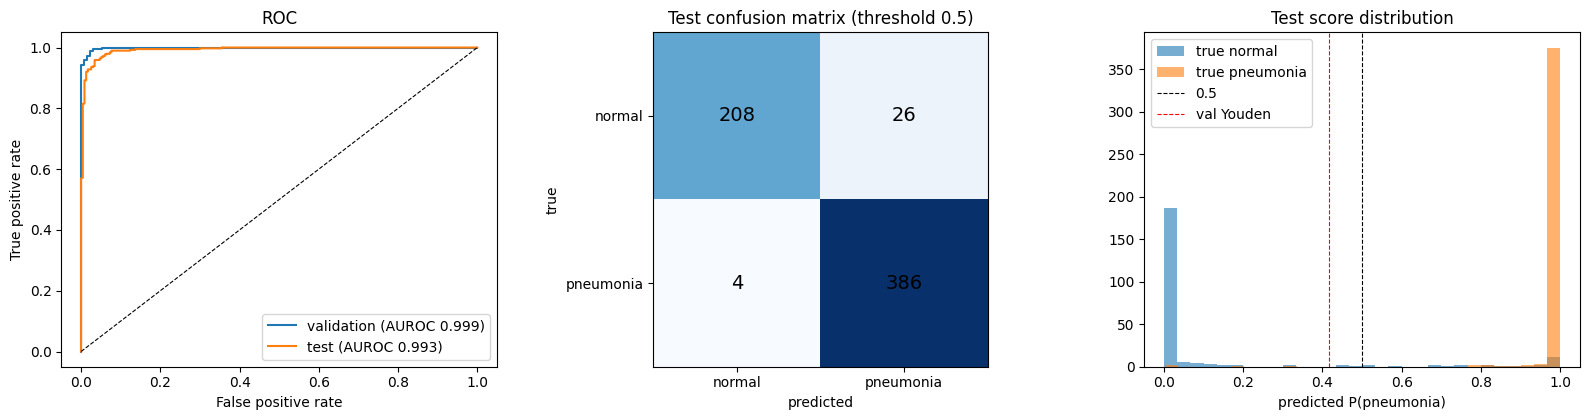

30 misclassified test images; showing up to 12


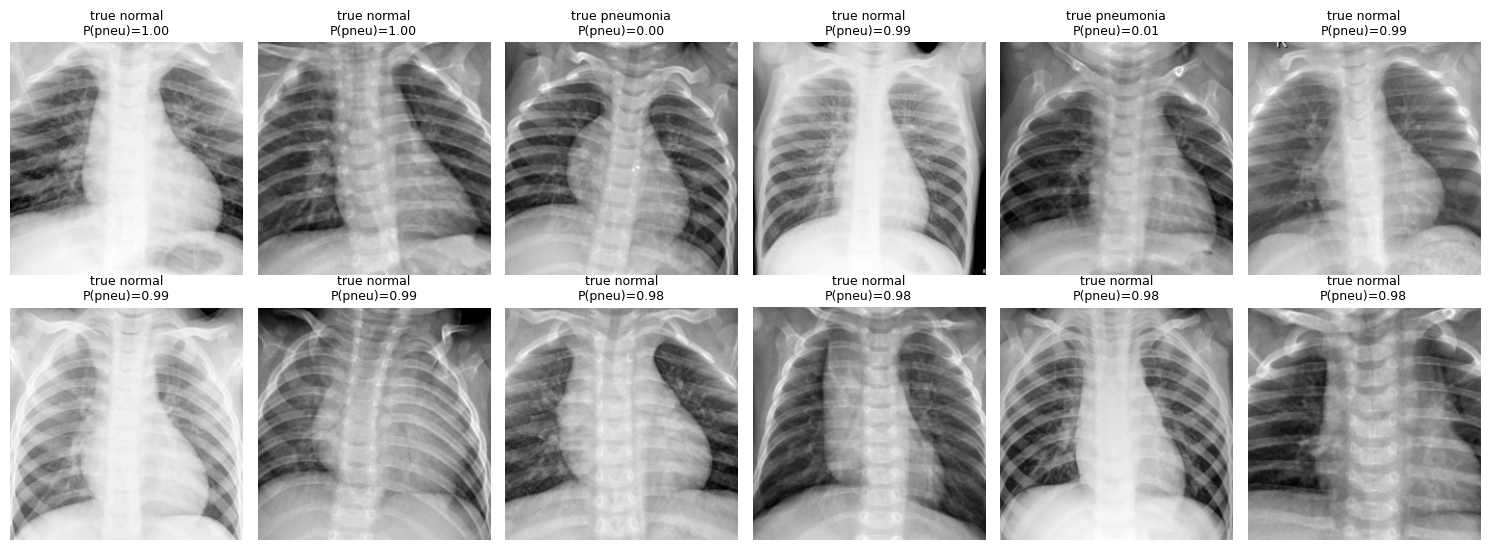

In [9]:
# ===== Cell 08 of 14: Q1: evaluation on validation and test =====
# Run the cells in order. Each cell uses variables created by the previous ones.

# ### 1.6 Evaluate on validation and test sets

val_loader = make_loader(data["val"], 128)
test_loader = make_loader(data["test"], 128)
y_val, p_val = predict(model, val_loader, USE_AMP)
y_test, p_test = predict(model, test_loader, USE_AMP)

THR = CFG["threshold"]                      # main operating point (0.5)
thr_val = youden_threshold(y_val, p_val)    # secondary: chosen on validation only
results = pd.DataFrame({
    f"val @{THR}": compute_metrics(y_val, p_val, THR),
    f"test @{THR} (main)": compute_metrics(y_test, p_test, THR),
    f"test @val-Youden ({thr_val:.3f})": compute_metrics(y_test, p_test, thr_val),
}).T
display(results.round(4))
results.to_csv(f"{OUT_DIR}/baseline_results.csv")

# Reference point: always predicting the majority class (pneumonia)
majority_acc = (y_test == 1).mean()
print(f"Majority-class baseline accuracy on test: {majority_acc:.3f}")

lo, hi = bootstrap_ci(y_test, p_test, roc_auc_score)
print(f"Test AUROC = {roc_auc_score(y_test, p_test):.4f}  (95% bootstrap CI {lo:.4f} to {hi:.4f})")

# Calibration: are the predicted probabilities trustworthy as probabilities?
def expected_calibration_error(y, p, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1); ece = 0.0
    for lo_b, hi_b in zip(bins[:-1], bins[1:]):
        m = (p > lo_b) & (p <= hi_b) if lo_b > 0 else (p >= lo_b) & (p <= hi_b)
        if m.any():
            ece += m.mean() * abs(y[m].mean() - p[m].mean())
    return ece
brier = np.mean((p_test - y_test) ** 2)
print(f"Test calibration: Brier score = {brier:.4f}, expected calibration error (10 bins) = "
      f"{expected_calibration_error(y_test, p_test):.4f}")
wrong_main = (p_test >= THR).astype(int) != y_test
print(f"Confident errors (P > 0.9 or P < 0.1) among {wrong_main.sum()} test errors at {THR}: "
      f"{int((wrong_main & ((p_test > 0.9) | (p_test < 0.1))).sum())}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))

for name, (yy, pp) in {"validation": (y_val, p_val), "test": (y_test, p_test)}.items():
    fpr, tpr, _ = roc_curve(yy, pp)
    ax[0].plot(fpr, tpr, label=f"{name} (AUROC {roc_auc_score(yy, pp):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].set_title("ROC"); ax[0].legend()

cm = confusion_matrix(y_test, (p_test >= THR).astype(int))
ax[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax[1].text(j, i, str(v), ha="center", va="center", fontsize=14)
ax[1].set_xticks([0, 1], ["normal", "pneumonia"]); ax[1].set_yticks([0, 1], ["normal", "pneumonia"])
ax[1].set_xlabel("predicted"); ax[1].set_ylabel("true"); ax[1].set_title(f"Test confusion matrix (threshold {THR})")

for c in [0, 1]:
    ax[2].hist(p_test[y_test == c], bins=30, alpha=0.6, label=f"true {LABELS[c]}")
ax[2].axvline(0.5, color="k", ls="--", lw=0.8, label="0.5")
ax[2].axvline(thr_val, color="r", ls="--", lw=0.8, label="val Youden")
ax[2].set_xlabel("predicted P(pneumonia)"); ax[2].set_title("Test score distribution"); ax[2].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/baseline_evaluation.png", dpi=120); show_fig()

# Misclassified test images (most confident mistakes first)
X_test = data["test"][0]
pred_test = (p_test >= THR).astype(int)       # main operating point
wrong = np.where(pred_test != y_test)[0]
wrong = wrong[np.argsort(-np.abs(p_test[wrong] - 0.5))][:12]
print(f"{(pred_test != y_test).sum()} misclassified test images; showing up to 12")
if len(wrong):
    cols = 6; rows = int(np.ceil(len(wrong) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(15, 2.8 * rows), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, i in zip(axes.ravel(), wrong):
        ax.imshow(X_test[i], cmap="gray")
        ax.set_title(f"true {LABELS[y_test[i]]}\nP(pneu)={p_test[i]:.2f}", fontsize=9)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/misclassified_test.png", dpi=120); show_fig()

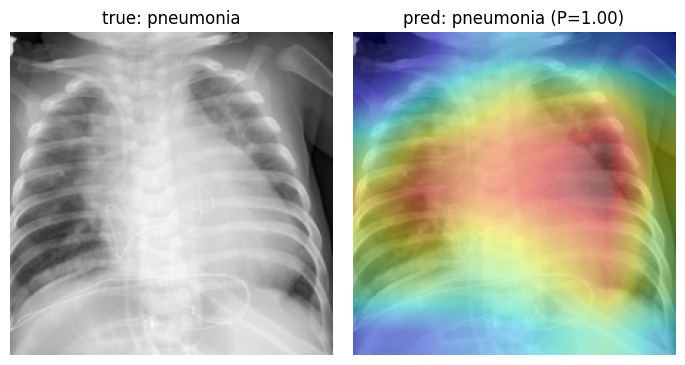

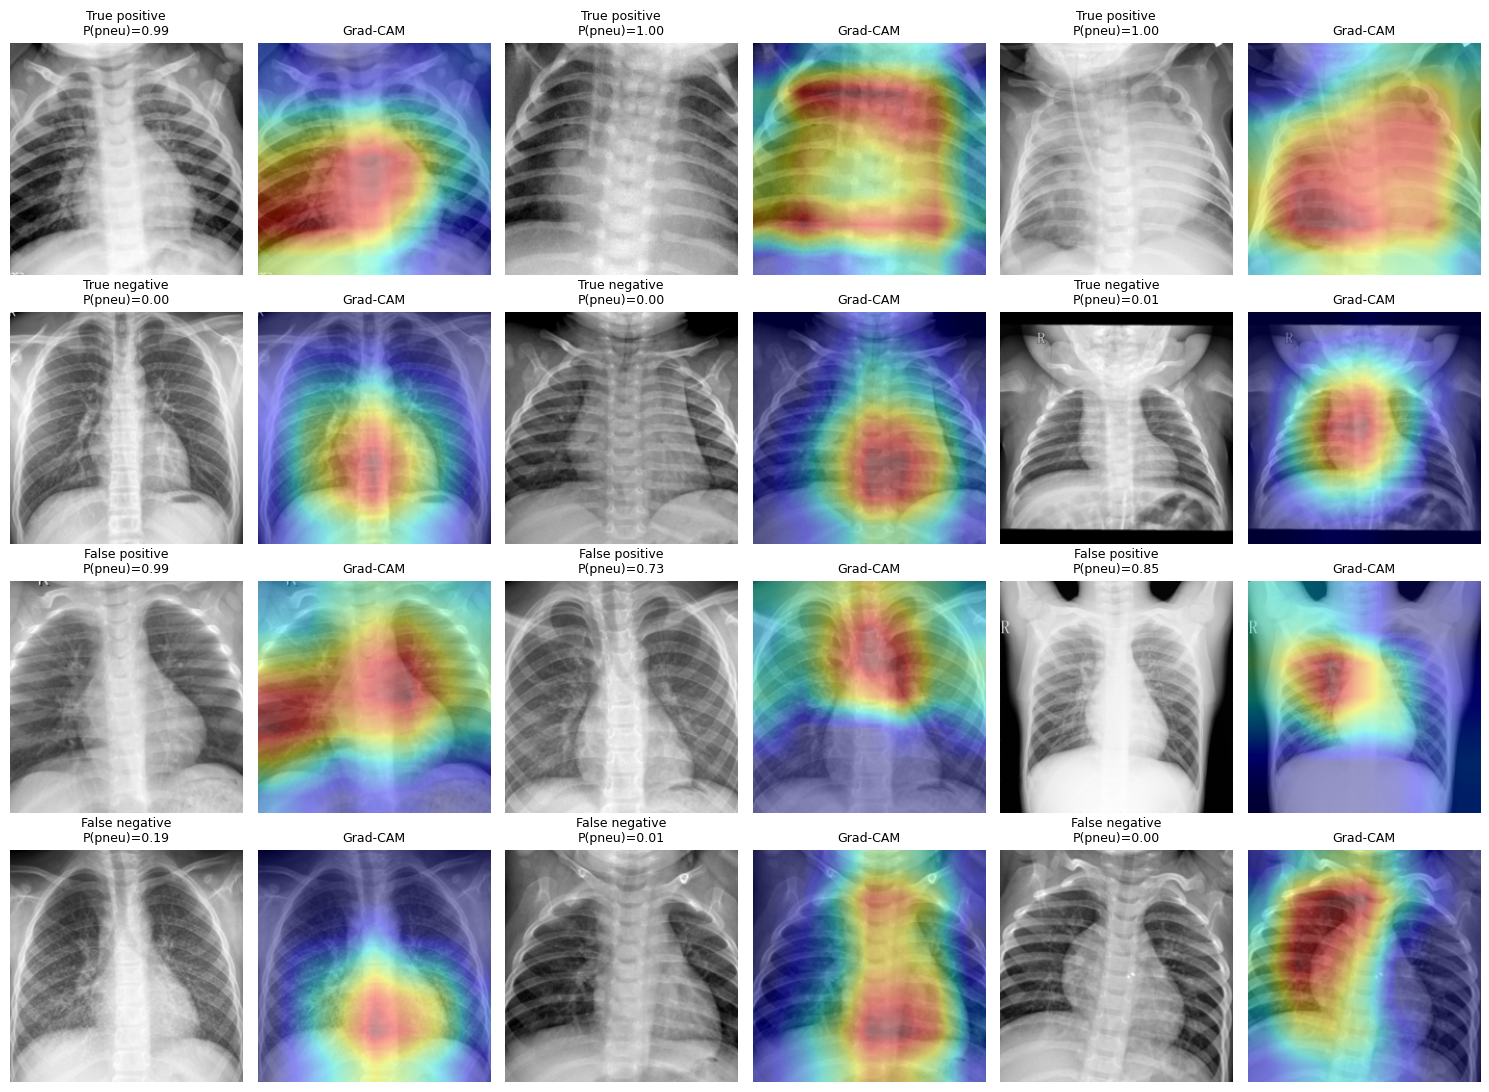

In [10]:
# ===== Cell 09 of 14: Q2: Grad-CAM explanations =====
# Run the cells in order. Each cell uses variables created by the previous ones.

# ## Question 2
# **2. Using the model from question 1, implement a function to explain its decisions using a model interpretability method (e.g., SHAP, LIME). Briefly explain your chosen method and what it tells you about your model.**
#
# Method used: **Grad-CAM** (Selvaraju et al., 2017), with two checks of whether the explanations can be trusted:
# a model-randomization sanity check (Adebayo et al., 2018) and a simple measure of how much attention falls on the image border.

class GradCAM:
    # Grad-CAM for a single-logit binary classifier.
    def __init__(self, model, target_layer):
        self.model, self.acts, self.grads = model, None, None
        self.handle = target_layer.register_forward_hook(self._hook)
    def _hook(self, module, inp, out):
        self.acts = out
        out.register_hook(lambda g: setattr(self, "grads", g))
    def __call__(self, x, target="predicted"):
        # target: "pneumonia", "normal" or "predicted"
        self.model.eval(); self.model.zero_grad(set_to_none=True)
        logit = self.model(x.to(DEVICE)).squeeze(1)              # full precision (no autocast)
        if target == "pneumonia":
            sign = torch.ones_like(logit)
        elif target == "normal":
            sign = -torch.ones_like(logit)
        else:
            sign = torch.where(logit >= 0, 1.0, -1.0)
        (sign * logit).sum().backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)            # channel importance
        cam = F.relu((w * self.acts).sum(dim=1, keepdim=True))  # weighted activation map
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False).squeeze(1)
        cam = cam - cam.amin(dim=(1, 2), keepdim=True)
        cam = cam / (cam.amax(dim=(1, 2), keepdim=True) + 1e-8)
        return cam.detach().cpu().numpy(), torch.sigmoid(logit).detach().cpu().numpy()
    def remove(self):
        self.handle.remove()

def explain_prediction(model, idx, split="test", target="predicted", thr=None, show=True):
    # Explain one prediction: returns (heatmap, P(pneumonia)) and optionally plots it.
    thr = THR if thr is None else thr
    X, y = data[split]
    x, _ = XrayDataset(X, y)[idx]
    cam_fn = GradCAM(model, model.layer4[-1])
    cam, prob = cam_fn(x.unsqueeze(0), target)
    cam_fn.remove()
    if show:
        pred = int(prob[0] >= thr)
        fig, ax = plt.subplots(1, 2, figsize=(7, 3.6))
        ax[0].imshow(X[idx], cmap="gray"); ax[0].set_title(f"true: {LABELS[y[idx]]}")
        ax[1].imshow(X[idx], cmap="gray"); ax[1].imshow(cam[0], cmap="jet", alpha=0.4)
        ax[1].set_title(f"pred: {LABELS[pred]} (P={prob[0]:.2f})")
        for a in ax: a.axis("off")
        plt.tight_layout(); plt.savefig(f"{OUT_DIR}/explain_{split}_{idx}.png", dpi=120); show_fig()
    return cam[0], float(prob[0])

# Example
_ = explain_prediction(model, int(np.where(y_test == 1)[0][0]))

# Gallery (threshold 0.5): 3 true positives, 3 true negatives, and up to 3 false positives / false negatives
groups = {
    "True positive":  np.where((y_test == 1) & (pred_test == 1))[0],
    "True negative":  np.where((y_test == 0) & (pred_test == 0))[0],
    "False positive": np.where((y_test == 0) & (pred_test == 1))[0],
    "False negative": np.where((y_test == 1) & (pred_test == 0))[0],
}
rng = np.random.default_rng(1)
fig, axes = plt.subplots(4, 6, figsize=(15, 11))
for r, (gname, idxs) in enumerate(groups.items()):
    chosen = rng.choice(idxs, min(3, len(idxs)), replace=False) if len(idxs) else []
    for k in range(3):
        a1, a2 = axes[r, 2 * k], axes[r, 2 * k + 1]
        a1.axis("off"); a2.axis("off")
        if k < len(chosen):
            i = int(chosen[k])
            cam, prob = explain_prediction(model, i, show=False)
            a1.imshow(X_test[i], cmap="gray"); a1.set_title(f"{gname}\nP(pneu)={prob:.2f}", fontsize=9)
            a2.imshow(X_test[i], cmap="gray"); a2.imshow(cam, cmap="jet", alpha=0.4)
            a2.set_title("Grad-CAM", fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/gradcam_gallery.png", dpi=120); show_fig()

Images predicted as pneumonia: 412 / 624
Randomization check on 32 predicted-pneumonia images: mean Pearson correlation trained vs random-weight maps = -0.386 (32 valid; 0 skipped because the random model gave a constant map). Near zero = explanations depend on the learned weights.

Border band covers 51% of the image area (uniform attention = 0.51).
                count   mean  median    min    max
group                                             
false positive   26.0  0.409   0.411  0.238  0.695
true positive   386.0  0.374   0.373  0.258  0.568
Predicted-pneumonia images above the uniform level: 4 / 412 (1.0%)
False vs true positives: median 0.411 vs 0.373, Mann-Whitney U p = 4.60e-02 (n = 26 vs 386)
Spearman correlation, P(pneumonia) vs border fraction: 0.022 (p = 6.6e-01)


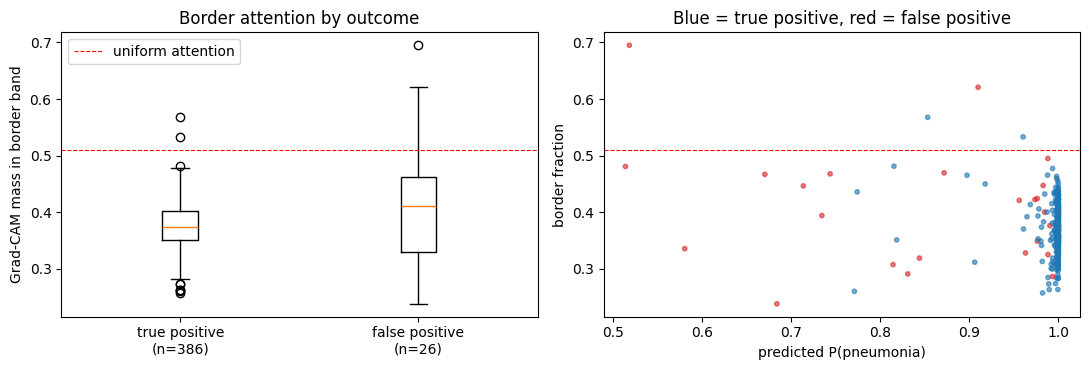

In [11]:
# ===== Cell 10 of 14: Q2: explanation sanity checks =====
# Run the cells in order. Each cell uses variables created by the previous ones.

from scipy.stats import mannwhitneyu, spearmanr

# Both checks use Grad-CAM for the PNEUMONIA class, so they are restricted to images the model
# predicts as pneumonia. For predicted-normal images the pneumonia map is nearly empty, and after
# normalization leftover noise spreads to the edges, which would distort both checks.
def batch_cams(m, idxs):
    cam_fn = GradCAM(m, m.layer4[-1])
    X, y = data["test"]
    xs = torch.stack([XrayDataset(X, y)[int(i)][0] for i in idxs])
    cams, _ = cam_fn(xs, "pneumonia"); cam_fn.remove()
    return cams

pneu_idx = np.where(pred_test == 1)[0]            # predicted pneumonia at the main threshold
print(f"Images predicted as pneumonia: {len(pneu_idx)} / {len(pred_test)}")
if len(pneu_idx) < 3:
    raise RuntimeError("Too few predicted-pneumonia images for the sanity checks; check the model in cell 07.")

# ---- Sanity check 1: model randomization (Adebayo et al., 2018) ----
# Explanations should change when the learned weights are destroyed. If a randomly initialized
# model gives similar maps, the maps reflect image structure rather than what the model learned.
sample_idx = np.random.default_rng(2).choice(pneu_idx, min(32, len(pneu_idx)), replace=False)
cams_trained = batch_cams(model, sample_idx)
random_model = build_model(pretrained=False).to(DEVICE)
cams_random = batch_cams(random_model, sample_idx)
with np.errstate(invalid="ignore", divide="ignore"):
    corr = np.array([np.corrcoef(a.ravel(), b.ravel())[0, 1] for a, b in zip(cams_trained, cams_random)])
valid = ~np.isnan(corr)
print(f"Randomization check on {len(sample_idx)} predicted-pneumonia images: mean Pearson correlation "
      f"trained vs random-weight maps = {corr[valid].mean():.3f} "
      f"({valid.sum()} valid; {(~valid).sum()} skipped because the random model gave a constant map). "
      "Near zero = explanations depend on the learned weights.")
del random_model

# ---- Sanity check 2: border attention (heuristic shortcut check) ----
# Share of Grad-CAM mass in the outer 15% band of the image. The band covers 51% of the area,
# so uniform attention would give 0.51. Higher values mean attention drifts toward the edges,
# where side markers and non-lung structures appear.
def border_fraction(cam, frac=0.15):
    h, w = cam.shape; bh, bw = int(h * frac), int(w * frac)
    inner = cam[bh:h - bh, bw:w - bw].sum()
    return 1 - inner / (cam.sum() + 1e-8)

area_share = 1 - (1 - 2 * 0.15) ** 2
bf = []
for start in range(0, len(pneu_idx), 64):
    for cam in batch_cams(model, pneu_idx[start:start + 64]):
        bf.append(border_fraction(cam))
bf = np.array(bf)

border_df = pd.DataFrame({"index": pneu_idx, "border_fraction": bf, "label": y_test[pneu_idx],
                          "p_pneumonia": p_test[pneu_idx]})
border_df["group"] = np.where(border_df.label == 1, "true positive", "false positive")
border_df.to_csv(f"{OUT_DIR}/gradcam_border_fraction.csv", index=False)

print(f"\nBorder band covers {area_share:.0%} of the image area (uniform attention = {area_share:.2f}).")
summary_bf = border_df.groupby("group").border_fraction.describe()[["count", "mean", "50%", "min", "max"]]
display(summary_bf.rename(columns={"50%": "median"}).round(3))
print(f"Predicted-pneumonia images above the uniform level: {(bf > area_share).sum()} / {len(bf)} "
      f"({(bf > area_share).mean():.1%})")

tp_bf = border_df.loc[border_df.group == "true positive", "border_fraction"]
fp_bf = border_df.loc[border_df.group == "false positive", "border_fraction"]
if len(fp_bf) >= 3 and len(tp_bf) >= 3:
    u = mannwhitneyu(fp_bf, tp_bf, alternative="two-sided")
    print(f"False vs true positives: median {fp_bf.median():.3f} vs {tp_bf.median():.3f}, "
          f"Mann-Whitney U p = {u.pvalue:.2e} (n = {len(fp_bf)} vs {len(tp_bf)})")
rho = spearmanr(border_df.p_pneumonia, border_df.border_fraction)
print(f"Spearman correlation, P(pneumonia) vs border fraction: {rho.statistic:.3f} (p = {rho.pvalue:.1e})")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
groups_bf = [tp_bf.values, fp_bf.values]
ax[0].boxplot(groups_bf, showfliers=True)
ax[0].set_xticks([1, 2], [f"true positive\n(n={len(tp_bf)})", f"false positive\n(n={len(fp_bf)})"])
ax[0].axhline(area_share, color="r", ls="--", lw=0.8, label="uniform attention")
ax[0].set_ylabel("Grad-CAM mass in border band"); ax[0].legend(); ax[0].set_title("Border attention by outcome")
colors = np.where(border_df.label == 1, "tab:blue", "tab:red")
ax[1].scatter(border_df.p_pneumonia, border_df.border_fraction, c=colors, s=10, alpha=0.6)
ax[1].axhline(area_share, color="r", ls="--", lw=0.8)
ax[1].set_xlabel("predicted P(pneumonia)"); ax[1].set_ylabel("border fraction")
ax[1].set_title("Blue = true positive, red = false positive")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/gradcam_border_analysis.png", dpi=120); show_fig()

Occlusion maps for 412 predicted-pneumonia images in 1.7 min (0 skipped: hiding any single patch did not lower the prediction)

Agreement between Grad-CAM and occlusion (Spearman correlation of the two maps, per image):
                count   mean  median
group                               
false positive   26.0  0.557   0.589
true positive   386.0  0.520   0.549

Border attention (uniform = 0.51), median by group:
                border_gradcam  border_occlusion
group                                           
false positive           0.411             0.212
true positive            0.373             0.407
Occlusion: false vs true positives, median border 0.212 vs 0.407, Mann-Whitney U p = 3.91e-07 (n = 26 vs 386)


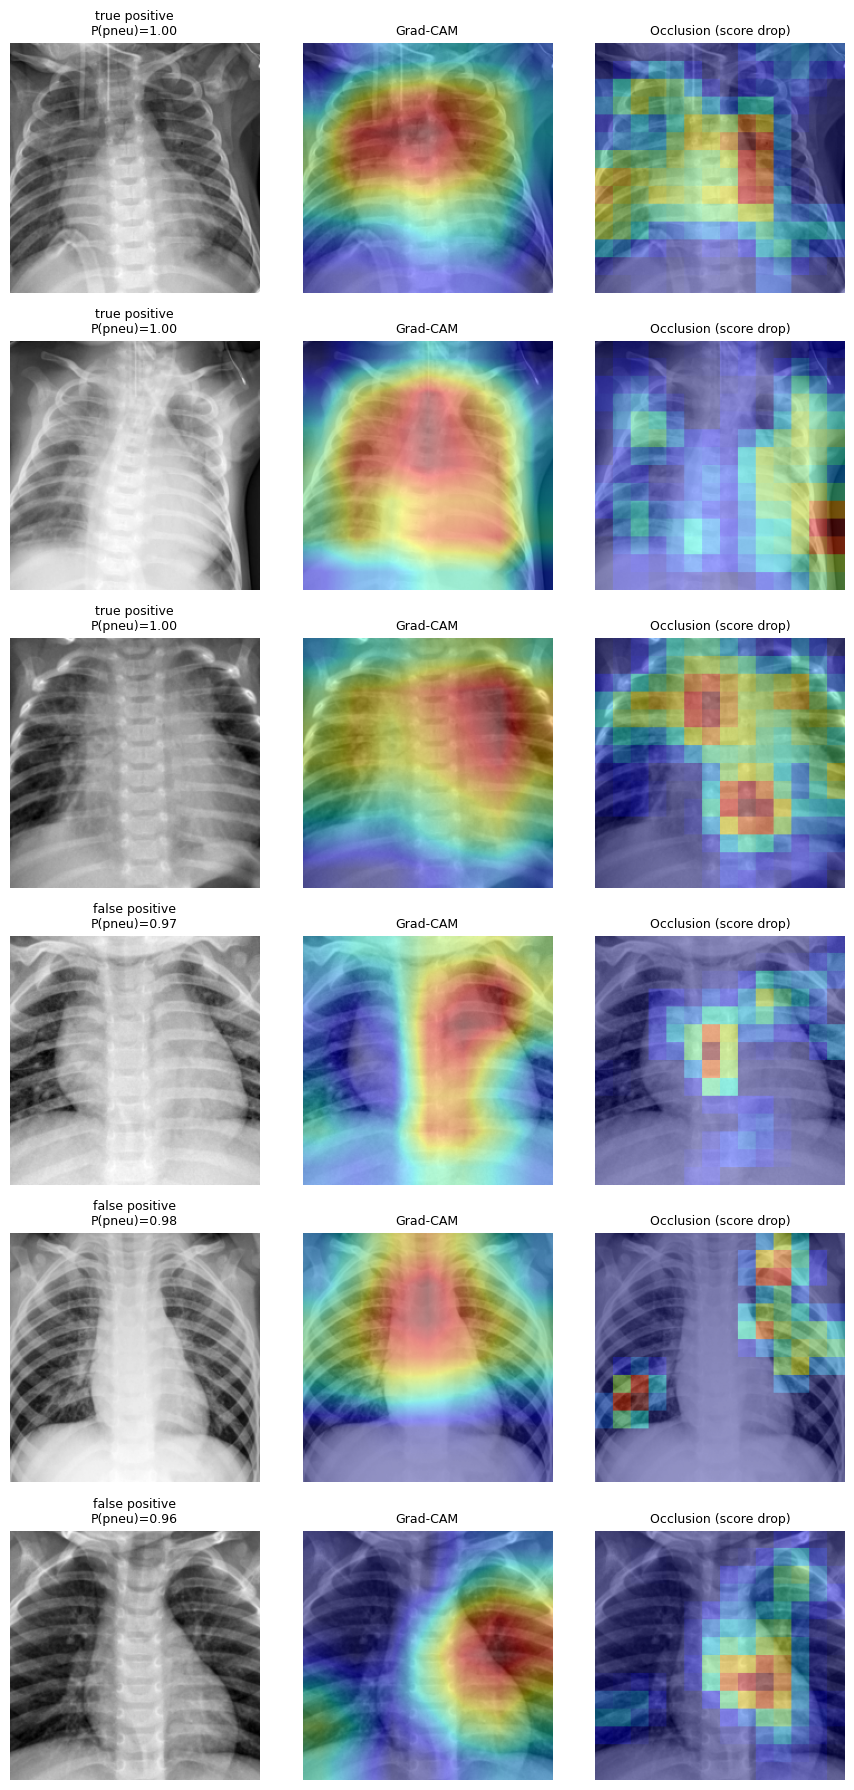

In [12]:
# ===== Cell 10b: Q2: cross-check Grad-CAM with occlusion sensitivity =====
# Run after cell 10. Uses the model, pneu_idx, batch_cams, border_fraction and area_share from earlier cells.

# Occlusion sensitivity (Zeiler & Fergus, 2014): slide a grey patch over the image and record how much
# the model's pneumonia score (logit) drops when each region is hidden. The logit is used instead of the
# probability because very confident predictions (P close to 1) barely change in probability. Regions whose removal lowers the prediction most are the
# ones the model relies on. It uses no gradients, so it is an independent check on Grad-CAM.

PATCH, STRIDE = 32, 16      # 32x32 patch moved in steps of 16 px -> 13 x 13 = 169 positions per image

@torch.no_grad()
def occlusion_map(x):
    # x: one normalized image (3, H, W). Grey = 0 in normalized space (the ImageNet mean).
    model.eval()
    H, W = x.shape[-2:]
    positions = [(r, c) for r in range(0, H - PATCH + 1, STRIDE) for c in range(0, W - PATCH + 1, STRIDE)]
    batch = x.unsqueeze(0).repeat(len(positions) + 1, 1, 1, 1)     # first copy stays unoccluded
    for k, (r, c) in enumerate(positions, start=1):
        batch[k, :, r:r + PATCH, c:c + PATCH] = 0.0
    z = model(batch.to(DEVICE)).squeeze(1).float().cpu().numpy()   # full precision, pneumonia logit
    drop = np.clip(z[0] - z[1:], 0, None)                          # how much hiding each patch lowers the score
    heat, count = np.zeros((H, W)), np.zeros((H, W))
    for d, (r, c) in zip(drop, positions):
        heat[r:r + PATCH, c:c + PATCH] += d
        count[r:r + PATCH, c:c + PATCH] += 1
    return heat / np.maximum(count, 1)

def downsample(m, size=28):
    return F.interpolate(torch.tensor(m)[None, None].float(), size=(size, size), mode="area")[0, 0].numpy()

X_te, y_te = data["test"]
ds_test = XrayDataset(X_te, y_te)
rows = []
t0 = time.time()
for start in range(0, len(pneu_idx), 64):
    idxs = pneu_idx[start:start + 64]
    cams = batch_cams(model, idxs)                                 # Grad-CAM for the pneumonia class
    for i, cam in zip(idxs, cams):
        occ = occlusion_map(ds_test[int(i)][0])
        valid = occ.sum() > 0
        rho = spearmanr(downsample(cam).ravel(), downsample(occ).ravel()).statistic if valid else np.nan
        rows.append(dict(index=int(i), label=int(y_te[i]), p_pneumonia=float(p_test[i]),
                         gradcam_vs_occlusion_spearman=rho,
                         border_gradcam=border_fraction(cam),
                         border_occlusion=border_fraction(occ) if valid else np.nan))
occ_df = pd.DataFrame(rows)
occ_df["group"] = np.where(occ_df.label == 1, "true positive", "false positive")
occ_df.to_csv(f"{OUT_DIR}/occlusion_check.csv", index=False)
print(f"Occlusion maps for {len(occ_df)} predicted-pneumonia images in {(time.time() - t0) / 60:.1f} min "
      f"({occ_df.border_occlusion.isna().sum()} skipped: hiding any single patch did not lower the prediction)")

# 1) Do the two methods agree on where the evidence is?
print("\nAgreement between Grad-CAM and occlusion (Spearman correlation of the two maps, per image):")
display(occ_df.groupby("group").gradcam_vs_occlusion_spearman.describe()[["count", "mean", "50%"]]
        .rename(columns={"50%": "median"}).round(3))

# 2) Does the border finding hold with the second method?
print(f"\nBorder attention (uniform = {area_share:.2f}), median by group:")
display(occ_df.groupby("group")[["border_gradcam", "border_occlusion"]].median().round(3))
tp_o = occ_df.loc[occ_df.group == "true positive", "border_occlusion"].dropna()
fp_o = occ_df.loc[occ_df.group == "false positive", "border_occlusion"].dropna()
if len(fp_o) >= 3 and len(tp_o) >= 3:
    u = mannwhitneyu(fp_o, tp_o, alternative="two-sided")
    print(f"Occlusion: false vs true positives, median border {fp_o.median():.3f} vs {tp_o.median():.3f}, "
          f"Mann-Whitney U p = {u.pvalue:.2e} (n = {len(fp_o)} vs {len(tp_o)})")

# 3) Side-by-side figure: 3 true positives and 3 false positives
rng = np.random.default_rng(3)
show = []
for g in ["true positive", "false positive"]:
    cand = occ_df[(occ_df.group == g) & occ_df.border_occlusion.notna()]["index"].values
    show += [(g, int(i)) for i in rng.choice(cand, min(3, len(cand)), replace=False)]
if not show:
    print("No valid occlusion maps to plot.")
fig, axes = plt.subplots(max(len(show), 1), 3, figsize=(9, 3 * max(len(show), 1)), squeeze=False)
for r, (g, i) in enumerate(show):
    cam = batch_cams(model, [i])[0]
    occ = occlusion_map(ds_test[i][0])
    axes[r, 0].imshow(X_te[i], cmap="gray"); axes[r, 0].set_title(f"{g}\nP(pneu)={p_test[i]:.2f}", fontsize=9)
    axes[r, 1].imshow(X_te[i], cmap="gray"); axes[r, 1].imshow(cam, cmap="jet", alpha=0.4)
    axes[r, 1].set_title("Grad-CAM", fontsize=9)
    axes[r, 2].imshow(X_te[i], cmap="gray"); axes[r, 2].imshow(occ, cmap="jet", alpha=0.4)
    axes[r, 2].set_title("Occlusion (score drop)", fontsize=9)
    for a in axes[r]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/gradcam_vs_occlusion.png", dpi=120); show_fig()

  0%|          | 0/20 [00:00<?, ?it/s]

    number  val_loss params_aug  params_batch_size  params_dropout  params_lr  params_weight_decay  user_attrs_best_epoch  user_attrs_val_auroc_at_best     state
19      19  0.022359       none                 64        0.066923   0.000205             0.000012                    6.0                      0.999708  COMPLETE
15      15  0.023118       none                 32        0.071804   0.000275             0.000626                    5.0                      0.999689  COMPLETE
1        1  0.023443       none                 64        0.091702   0.000159             0.000680                    6.0                      0.999728  COMPLETE
2        2  0.028561       none                 32        0.183181   0.000041             0.000126                    6.0                      0.999436  COMPLETE
0        0  0.029142       none                 32        0.433088   0.000056             0.006351                    6.0                      0.999572  COMPLETE
11      11  0.029630       n

/tmp/ipykernel_22/3314764602.py:47: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study); plt.tight_layout()


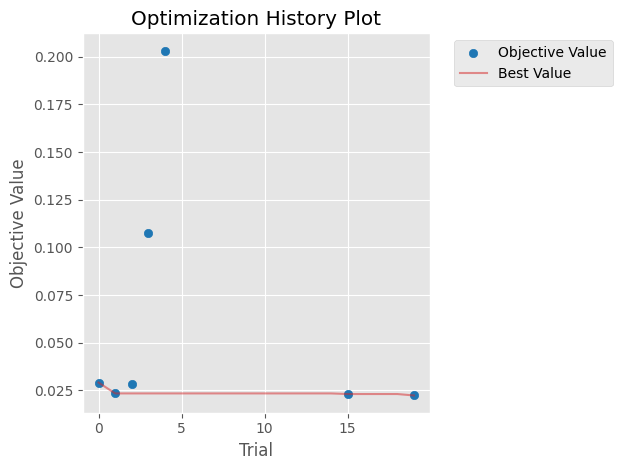

/tmp/ipykernel_22/3314764602.py:50: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study); plt.tight_layout()


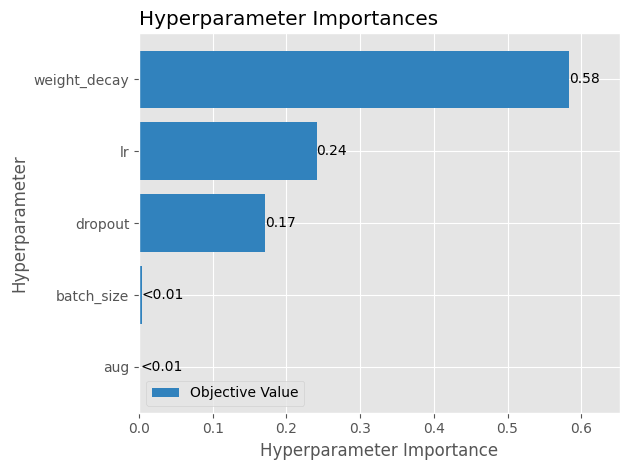

In [13]:
# ===== Cell 11 of 14: Q3: hyperparameter search =====
# Run the cells in order. Each cell uses variables created by the previous ones.

# ## Question 3
# **3. Using the model from question 1, demonstrate your ability to optimize its performance (in terms of accuracy and/or speed) through hyperparameter tuning.**
#
# Part A tunes for accuracy with Optuna, minimizing VALIDATION LOSS (validation AUROC is ~0.999 and too
# saturated to separate configurations). Each trial trains 8 epochs, closer to the 12-epoch final training,
# so the search does not simply reward settings that learn fastest. The test set is not used for tuning.
# Part B measures speed: mixed precision, memory layout and input resolution.

# ### 3A. Accuracy: Bayesian hyperparameter search (Optuna, TPE sampler + median pruning)

def objective(trial):
    cfg = dict(CFG)
    cfg.update(
        lr=trial.suggest_float("lr", 1e-5, 1e-3, log=True),
        weight_decay=trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
        batch_size=trial.suggest_categorical("batch_size", [32, 64]),
        aug=trial.suggest_categorical("aug", ["none", "light", "strong"]),
        dropout=trial.suggest_float("dropout", 0.0, 0.5),
        epochs=CFG["trial_epochs"], patience=CFG["trial_epochs"],
    )
    _, hist, best_loss = train_model(cfg, data, verbose=False, trial=trial)
    trial.set_user_attr("val_auroc_at_best", float(hist.loc[hist.selected, "val_auroc"].iloc[0]))
    trial.set_user_attr("best_epoch", int(hist.loc[hist.selected, "epoch"].iloc[0]))
    return best_loss

optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="minimize",
                            sampler=optuna.samplers.TPESampler(seed=CFG["seed"]),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2))
t0 = time.time()
study.optimize(objective, n_trials=CFG["n_trials"], gc_after_trial=True, show_progress_bar=True)
search_minutes = (time.time() - t0) / 60

trials_df = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "state"))
trials_df = trials_df.rename(columns={"value": "val_loss"})
trials_df.to_csv(f"{OUT_DIR}/optuna_trials.csv", index=False)
display(trials_df.sort_values("val_loss").head(10))
print(trials_df.groupby(["params_aug", "state"]).size().rename("trials").to_string())
print(f"search time {search_minutes:.1f} min | best validation loss {study.best_value:.4f}")
print("best params:", study.best_params)

try:
    from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances
    plot_optimization_history(study); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/optuna_history.png", dpi=120); show_fig()
    if len([t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]) >= 3:
        plot_param_importances(study); plt.tight_layout()
        plt.savefig(f"{OUT_DIR}/optuna_importance.png", dpi=120); show_fig()
except Exception as e:
    print("Plotting skipped:", e)

In [14]:
# ===== Cell 12 of 14: Q3: retrain best config, compare with baseline over several seeds =====
# Run the cells in order. Each cell uses variables created by the previous ones.

import gc

# Single runs differ by chance (random initialization order, augmentation, data order, GPU
# nondeterminism). To tell a real improvement from run-to-run noise, the baseline and the tuned
# configuration are each trained with the same 3 seeds and evaluated at the main threshold (0.5).

def run_seeds(cfg, data_dict, seeds, name, save_first=None):
    rows, probs = [], {}
    test_ld = make_loader(data_dict["test"], 128)
    for i, sd in enumerate(seeds):
        c = dict(cfg); c["seed"] = sd
        t0 = time.time()
        m, hist, _ = train_model(c, data_dict, verbose=False)
        minutes = (time.time() - t0) / 60
        yt, pt = predict(m, test_ld, c["amp"] and DEVICE.type == "cuda")
        sel = hist[hist.selected].iloc[0]
        met = compute_metrics(yt, pt, CFG["threshold"])
        rows.append(dict(config=name, seed=sd, kept_epoch=int(sel.epoch), val_loss=sel.val_loss,
                         val_AUROC=sel.val_auroc, test_AUROC=met["AUROC"], test_AUPRC=met["AUPRC"],
                         test_accuracy=met["accuracy"], test_balanced_accuracy=met["balanced_accuracy"],
                         test_sensitivity=met["sensitivity"], test_specificity=met["specificity"],
                         test_F1=met["F1"], FP=met["FP"], FN=met["FN"], train_minutes=minutes))
        probs[sd] = (yt, pt)
        if save_first and i == 0:
            torch.save(m.state_dict(), save_first)
        print(f"  {name} seed {sd}: test AUROC {met['AUROC']:.4f}, accuracy {met['accuracy']:.4f}, "
              f"FP {met['FP']}, FN {met['FN']} ({minutes:.1f} min)")
        del m
        gc.collect()
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return pd.DataFrame(rows), probs

def mean_std(df, cols):
    g = df.groupby("config", sort=False)[cols]
    out = g.mean().round(4).astype(str) + " ± " + g.std().round(4).astype(str)
    return out

tuned_cfg = dict(CFG); tuned_cfg.update(study.best_params)
print("Tuned configuration:", {k: tuned_cfg[k] for k in ["lr", "weight_decay", "batch_size", "aug", "dropout"]})
print("Baseline configuration:", {k: CFG[k] for k in ["lr", "weight_decay", "batch_size", "aug", "dropout"]})

baseline_runs, baseline_probs = run_seeds(CFG, data, CFG["seeds"], "baseline")
tuned_runs, tuned_probs = run_seeds(tuned_cfg, data, CFG["seeds"], "tuned",
                                    save_first=f"{OUT_DIR}/tuned_resnet18.pt")
seed_runs = pd.concat([baseline_runs, tuned_runs], ignore_index=True)
seed_runs.to_csv(f"{OUT_DIR}/baseline_vs_tuned_per_seed.csv", index=False)

cols = ["val_loss", "val_AUROC", "test_AUROC", "test_AUPRC", "test_accuracy", "test_balanced_accuracy",
        "test_sensitivity", "test_specificity", "test_F1", "FP", "FN"]
print(f"\nMean ± standard deviation over seeds {CFG['seeds']} (threshold {CFG['threshold']}):")
comparison = mean_std(seed_runs, cols)
display(comparison)
comparison.to_csv(f"{OUT_DIR}/baseline_vs_tuned.csv")

# Paired differences (same seed, tuned minus baseline)
paired = tuned_runs.set_index("seed")[["test_AUROC", "test_accuracy", "test_specificity"]] - \
         baseline_runs.set_index("seed")[["test_AUROC", "test_accuracy", "test_specificity"]]
print("\nPaired difference per seed (tuned minus baseline):")
display(paired.round(4))
print("Tuned better on test AUROC in", int((paired.test_AUROC > 0).sum()), "of", len(paired), "seeds.")

# Bootstrap CI for the first seed of each configuration, for reference
for name, probs in [("baseline", baseline_probs), ("tuned", tuned_probs)]:
    sd = CFG["seeds"][0]; yy, pp = probs[sd]
    lo, hi = bootstrap_ci(yy, pp, roc_auc_score)
    print(f"{name:8s} seed {sd}: test AUROC {roc_auc_score(yy, pp):.4f} (95% bootstrap CI {lo:.4f} to {hi:.4f})")

Tuned configuration: {'lr': 0.0002046527470297333, 'weight_decay': 1.1661881989438902e-05, 'batch_size': 64, 'aug': 'none', 'dropout': 0.06692293105725108}
Baseline configuration: {'lr': 0.0001, 'weight_decay': 0.0001, 'batch_size': 64, 'aug': 'light', 'dropout': 0.0}
  baseline seed 42: test AUROC 0.9926, accuracy 0.9519, FP 26, FN 4 (1.3 min)
  baseline seed 43: test AUROC 0.9935, accuracy 0.9567, FP 26, FN 1 (1.3 min)
  baseline seed 44: test AUROC 0.9937, accuracy 0.9519, FP 26, FN 4 (1.3 min)
  tuned seed 42: test AUROC 0.9873, accuracy 0.9151, FP 53, FN 0 (1.5 min)
  tuned seed 43: test AUROC 0.9900, accuracy 0.9183, FP 50, FN 1 (1.3 min)
  tuned seed 44: test AUROC 0.9812, accuracy 0.9071, FP 58, FN 0 (1.0 min)

Mean ± standard deviation over seeds [42, 43, 44] (threshold 0.5):
                 val_loss        val_AUROC       test_AUROC       test_AUPRC    test_accuracy test_balanced_accuracy test_sensitivity test_specificity          test_F1                FP               FN
c

In [15]:
# ===== Cell 12b: Q3: ensemble of the baseline seeds =====
# Run after cell 12. Averages the test predictions of the 3 baseline models trained in cell 12 (no retraining).
# Decided in advance: threshold stays 0.5, and the result is reported whether or not it improves.

y_ens = baseline_probs[CFG["seeds"][0]][0]
p_ens = np.mean([baseline_probs[s][1] for s in CFG["seeds"]], axis=0)

def summarize(name, y, p):
    m = compute_metrics(y, p, CFG["threshold"])
    wrong = (p >= CFG["threshold"]).astype(int) != y
    return dict(model=name, test_AUROC=m["AUROC"], test_accuracy=m["accuracy"],
                sensitivity=m["sensitivity"], specificity=m["specificity"], FP=m["FP"], FN=m["FN"],
                brier=np.mean((p - y) ** 2), ECE=expected_calibration_error(y, p),
                confident_errors=int((wrong & ((p > 0.9) | (p < 0.1))).sum()), errors=int(wrong.sum()))

ens_rows = [summarize(f"baseline seed {s}", *baseline_probs[s]) for s in CFG["seeds"]]
ens_rows.append(summarize(f"ensemble (mean of {len(CFG['seeds'])} seeds)", y_ens, p_ens))
ensemble_df = pd.DataFrame(ens_rows).set_index("model")
display(ensemble_df.round(4))
ensemble_df.to_csv(f"{OUT_DIR}/ensemble_results.csv")

lo, hi = bootstrap_ci(y_ens, p_ens, roc_auc_score)
print(f"Ensemble test AUROC {roc_auc_score(y_ens, p_ens):.4f} (95% bootstrap CI {lo:.4f} to {hi:.4f})")

                            test_AUROC  test_accuracy  sensitivity  specificity  FP  FN   brier     ECE  confident_errors  errors
model                                                                                                                            
baseline seed 42                0.9926         0.9519       0.9897       0.8889  26   4  0.0384  0.0368                16      30
baseline seed 43                0.9935         0.9567       0.9974       0.8889  26   1  0.0386  0.0404                17      27
baseline seed 44                0.9937         0.9519       0.9897       0.8889  26   4  0.0374  0.0385                14      30
ensemble (mean of 3 seeds)      0.9945         0.9551       0.9897       0.8974  24   4  0.0352  0.0391                13      28
Ensemble test AUROC 0.9945 (95% bootstrap CI 0.9907 to 0.9977)


In [16]:
# ===== Cell 13 of 14: Q3: speed benchmarks and trade-offs =====
# Run the cells in order. Each cell uses variables created by the previous ones.

# ### 3B. Speed: mixed precision, memory layout and input resolution

def benchmark(amp, channels_last, img_size=224, batch_size=64, iters=40, warmup=10):
    # Training and inference throughput (images/second) on a fixed synthetic batch,
    # which isolates GPU compute from data loading.
    m = build_model().to(DEVICE)
    x = torch.randn(batch_size, 3, img_size, img_size, device=DEVICE)
    y = torch.randint(0, 2, (batch_size,), device=DEVICE).float()
    if channels_last:
        m = m.to(memory_format=torch.channels_last); x = x.contiguous(memory_format=torch.channels_last)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-4)
    scaler = torch.amp.GradScaler("cuda", enabled=amp and DEVICE.type == "cuda")
    crit = nn.BCEWithLogitsLoss()

    def sync():
        if DEVICE.type == "cuda": torch.cuda.synchronize()

    m.train()
    for i in range(warmup + iters):
        if i == warmup:
            sync(); t0 = time.time()
        opt.zero_grad(set_to_none=True)
        with autocast_ctx(amp):
            loss = crit(m(x).squeeze(1), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
    sync(); train_ips = iters * batch_size / (time.time() - t0)

    m.eval()
    with torch.no_grad():
        for i in range(warmup + iters):
            if i == warmup:
                sync(); t0 = time.time()
            with autocast_ctx(amp):
                m(x)
    sync(); infer_ips = iters * batch_size / (time.time() - t0)

    peak_mb = torch.cuda.max_memory_allocated() / 2**20 if DEVICE.type == "cuda" else float("nan")
    if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
    del m, opt; torch.cuda.empty_cache() if DEVICE.type == "cuda" else None
    return dict(train_img_per_s=train_ips, infer_img_per_s=infer_ips, peak_mem_MB=peak_mb)

iters = 5 if FAST_DEV_RUN else 40
speed = pd.DataFrame({
    "FP32":                    benchmark(amp=False, channels_last=False, iters=iters),
    "AMP (FP16)":              benchmark(amp=True,  channels_last=False, iters=iters),
    "AMP + channels_last":     benchmark(amp=True,  channels_last=True,  iters=iters),
    "AMP, 128 px input":       benchmark(amp=True,  channels_last=False, img_size=128, iters=iters),
}).T
speed["train_speedup_vs_FP32"] = speed.train_img_per_s / speed.loc["FP32", "train_img_per_s"]
display(speed.round(2))
speed.to_csv(f"{OUT_DIR}/speed_benchmark.csv")

# Does mixed precision or a lower resolution change accuracy? Each configuration is trained with the
# same seeds as the baseline (AMP, 224 px), so differences can be compared with run-to-run variation.
tradeoff_runs = [baseline_runs.assign(config="AMP, 224 px (baseline)")]

if RUN_FP32_ACCURACY_CHECK and DEVICE.type == "cuda":
    fp32_cfg = dict(CFG); fp32_cfg["amp"] = False
    fp32_runs, _ = run_seeds(fp32_cfg, data, CFG["seeds"], "FP32, 224 px")
    tradeoff_runs.append(fp32_runs)

if RUN_RESOLUTION_EXPERIMENT:
    data128 = {s: load_split(s, 128) for s in ["train", "val", "test"]}
    if DEDUP_MASKS is not None:          # same duplicate removal as the 224 px data (same image order)
        for s in ["train", "val"]:
            data128[s] = (data128[s][0][DEDUP_MASKS[s]], data128[s][1][DEDUP_MASKS[s]])
    cfg128 = dict(CFG); cfg128["img_size"] = 128
    res_runs, _ = run_seeds(cfg128, data128, CFG["seeds"], "AMP, 128 px")
    tradeoff_runs.append(res_runs)

if len(tradeoff_runs) > 1:
    tradeoff_df = pd.concat(tradeoff_runs, ignore_index=True)
    tradeoff_df.to_csv(f"{OUT_DIR}/speed_accuracy_tradeoff_per_seed.csv", index=False)
    trade_off = mean_std(tradeoff_df, ["test_AUROC", "test_accuracy", "test_sensitivity",
                                       "test_specificity", "kept_epoch", "train_minutes"])
    print(f"\nMean ± standard deviation over seeds {CFG['seeds']}:")
    display(trade_off)
    trade_off.to_csv(f"{OUT_DIR}/speed_accuracy_tradeoff.csv")

                     train_img_per_s  infer_img_per_s  peak_mem_MB  train_speedup_vs_FP32
FP32                          331.56          1061.16      4152.34                   1.00
AMP (FP16)                    694.99          2155.34      1306.06                   2.10
AMP + channels_last           920.95          2565.96      1797.45                   2.78
AMP, 128 px input            1931.76          6307.45      1269.59                   5.83
  FP32, 224 px seed 42: test AUROC 0.9908, accuracy 0.9599, FP 22, FN 3 (3.2 min)
  FP32, 224 px seed 43: test AUROC 0.9940, accuracy 0.9567, FP 23, FN 4 (3.1 min)
  FP32, 224 px seed 44: test AUROC 0.9940, accuracy 0.9519, FP 26, FN 4 (2.6 min)


100%|██████████| 75.5M/75.5M [00:23<00:00, 3.28MB/s]


  AMP, 128 px seed 42: test AUROC 0.9862, accuracy 0.9295, FP 40, FN 4 (0.5 min)
  AMP, 128 px seed 43: test AUROC 0.9939, accuracy 0.9535, FP 24, FN 5 (0.8 min)
  AMP, 128 px seed 44: test AUROC 0.9887, accuracy 0.9455, FP 30, FN 4 (0.8 min)

Mean ± standard deviation over seeds [42, 43, 44]:
                             test_AUROC    test_accuracy test_sensitivity test_specificity       kept_epoch    train_minutes
config                                                                                                                      
AMP, 224 px (baseline)  0.9933 ± 0.0006  0.9535 ± 0.0028  0.9923 ± 0.0044     0.8889 ± 0.0        6.0 ± 0.0  1.3411 ± 0.0014
FP32, 224 px            0.9929 ± 0.0018   0.9562 ± 0.004  0.9906 ± 0.0015  0.8989 ± 0.0089  8.3333 ± 2.0817   2.9797 ± 0.326
AMP, 128 px             0.9896 ± 0.0039  0.9428 ± 0.0122  0.9889 ± 0.0015  0.8661 ± 0.0345     6.0 ± 4.3589    0.69 ± 0.1688


In [17]:
# ===== Cell 14 of 14: Save summary; references =====
# Run the cells in order. Each cell uses variables created by the previous ones.

def per_config(df):
    return {k: g.drop(columns=["config"]).mean(numeric_only=True).to_dict() for k, g in df.groupby("config")}

summary = dict(
    config=CFG,
    duplicates=dup_report,
    q1_baseline_seed42=dict(
        test_at_main_threshold=compute_metrics(y_test, p_test, THR),
        test_at_val_youden=compute_metrics(y_test, p_test, thr_val),
        val_AUROC=float(roc_auc_score(y_val, p_val)), train_minutes=baseline_train_minutes),
    q3_tuned_params=study.best_params,
    q3_mean_over_seeds=per_config(seed_runs),
    q3_speed_accuracy_mean_over_seeds=per_config(tradeoff_df) if "tradeoff_df" in globals() else None,
    optuna_search_minutes=search_minutes,
)
with open(f"{OUT_DIR}/summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=float)
print("Saved files:"); print("\n".join(sorted(os.listdir(OUT_DIR))))

# ## References
# 1. Kermany, D. S., et al. (2018). Identifying medical diagnoses and treatable diseases by image-based deep learning. *Cell*, 172(5), 1122-1131. https://doi.org/10.1016/j.cell.2018.02.010
# 2. Yang, J., et al. (2023). MedMNIST v2: A large-scale lightweight benchmark for 2D and 3D biomedical image classification. *Scientific Data*, 10, 41. https://arxiv.org/abs/2110.14795
# 3. He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep residual learning for image recognition. *CVPR*. https://arxiv.org/abs/1512.03385
# 4. Deng, J., et al. (2009). ImageNet: A large-scale hierarchical image database. *CVPR*.
# 5. Loshchilov, I., & Hutter, F. (2019). Decoupled weight decay regularization (AdamW). *ICLR*. https://arxiv.org/abs/1711.05101
# 6. Loshchilov, I., & Hutter, F. (2017). SGDR: Stochastic gradient descent with warm restarts (cosine annealing). *ICLR*. https://arxiv.org/abs/1608.03983
# 7. Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *ICLR*. https://arxiv.org/abs/1412.6980
# 8. Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE*. https://doi.org/10.1371/journal.pone.0118432
# 9. Youden, W. J. (1950). Index for rating diagnostic tests. *Cancer*, 3(1), 32-35.
# 10. Selvaraju, R. R., et al. (2017). Grad-CAM: Visual explanations from deep networks via gradient-based localization. *ICCV*. https://arxiv.org/abs/1610.02391
# 11. Adebayo, J., et al. (2018). Sanity checks for saliency maps. *NeurIPS*. https://arxiv.org/abs/1810.03292
# 12. Zech, J. R., et al. (2018). Variable generalization performance of a deep learning model to detect pneumonia in chest radiographs. *PLOS Medicine*. https://doi.org/10.1371/journal.pmed.1002683
# 13. Akiba, T., et al. (2019). Optuna: A next-generation hyperparameter optimization framework. *KDD*. https://arxiv.org/abs/1907.10902
# 14. Bergstra, J., Bardenet, R., Bengio, Y., & Kégl, B. (2011). Algorithms for hyper-parameter optimization (TPE). *NeurIPS*.
# 15. Micikevicius, P., et al. (2018). Mixed precision training. *ICLR*. https://arxiv.org/abs/1710.03740
# 16. PyTorch documentation: Automatic Mixed Precision (https://pytorch.org/docs/stable/amp.html) and channels_last memory format (https://pytorch.org/tutorials/intermediate/memory_format_tutorial.html).

Saved files:
baseline_evaluation.png
baseline_history.csv
baseline_resnet18.pt
baseline_results.csv
baseline_training_curves.png
baseline_vs_tuned.csv
baseline_vs_tuned_per_seed.csv
class_balance.csv
class_balance_original.csv
class_distribution.png
duplicate_report.csv
ensemble_results.csv
explain_test_0.png
gradcam_border_analysis.png
gradcam_border_fraction.csv
gradcam_gallery.png
gradcam_vs_occlusion.png
misclassified_test.png
occlusion_check.csv
optuna_history.png
optuna_importance.png
optuna_trials.csv
sample_images.png
speed_accuracy_tradeoff.csv
speed_accuracy_tradeoff_per_seed.csv
speed_benchmark.csv
summary.json
tuned_resnet18.pt
